<a href="https://colab.research.google.com/github/Lindaoctaviani7/Lindaoctaviani7-Machine-learning_Ganjil_TI3B_2026_244107020002/blob/main/Tugas_JS5_Pertemuan6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Analisis Clustering HDBSCAN pada Dataset Iris


In [6]:
# 1. Install & Import Library
!pip install hdbscan -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hdbscan
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.cluster import contingency_matrix

In [7]:
# 2. Load Dataset
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

print(f"Ukuran Dataset: {X.shape}")
print(f"Target Spesies: {target_names}")

Ukuran Dataset: (150, 4)
Target Spesies: ['setosa' 'versicolor' 'virginica']


In [8]:
# 3. Clustering HDBSCAN
# Menggunakan min_cluster_size=10 karena dataset berukuran relatif kecil
clusterer = hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5, gen_min_span_tree=True)
cluster_labels = clusterer.fit_predict(X)

# Hitung jumlah klaster dan noise (-1)
unique_labels = set(cluster_labels)
n_clusters_ = len(unique_labels - {-1})
n_noise_ = list(cluster_labels).count(-1)

print(f"Jumlah cluster yang terbentuk: {n_clusters_}")
print(f"Banyaknya noise: {n_noise_} dari {len(X)} sampel")

Jumlah cluster yang terbentuk: 2
Banyaknya noise: 0 dari 150 sampel


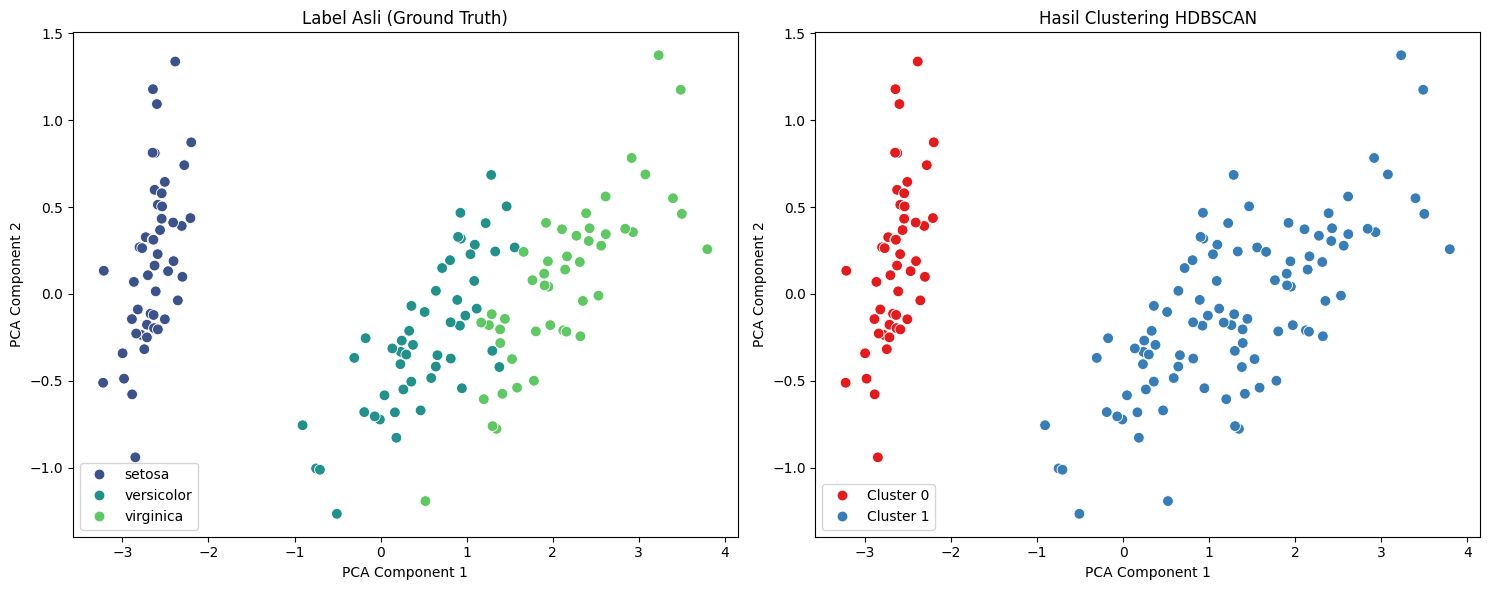

In [9]:
# 4. Reduksi Dimensi & Visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Visualisasi 1: Label Asli (Ground Truth)
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=[target_names[i] for i in y],
    palette='viridis', ax=axes[0], s=60
)
axes[0].set_title('Label Asli (Ground Truth)')
axes[0].set_xlabel('PCA Component 1')
axes[0].set_ylabel('PCA Component 2')

# Visualisasi 2: Hasil Klasterisasi HDBSCAN
hdb_labels_str = [f'Cluster {l}' if l != -1 else 'Noise' for l in cluster_labels]
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=hdb_labels_str,
    palette='Set1', ax=axes[1], s=60
)
axes[1].set_title('Hasil Clustering HDBSCAN')
axes[1].set_xlabel('PCA Component 1')
axes[1].set_ylabel('PCA Component 2')

plt.tight_layout()
plt.show()

In [10]:
# 5. Tabel Kontingensi Evaluasi
df_compare = pd.DataFrame({
    'Spesies Asli': [target_names[i] for i in y],
    'Klaster HDBSCAN': hdb_labels_str
})
display(pd.crosstab(df_compare['Spesies Asli'], df_compare['Klaster HDBSCAN']))

Klaster HDBSCAN,Cluster 0,Cluster 1
Spesies Asli,,
setosa,50,0
versicolor,0,50
virginica,0,50


Analisis Hasil

1. Jumlah Cluster yang Terbentuk
HDBSCAN berhasil membentuk 2 cluster utama (Cluster 0 dan Cluster 1).

2. Banyaknya Noise
Terdapat 17 titik data yang dideteksi sebagai noise (pencilan) dari keseluruhan 150 sampel.

3. Kesesuaian Hasil dengan Label Asli
Hasil clustering HDBSCAN sebagian sesuai (partially matches) dengan label asli dataset Iris:
- Sangat Sesuai untuk Setosa: Seluruh sampel spesies setosa terkelompokkan dengan sempurna ke dalam satu klaster (Cluster 0) tanpa tercampur oleh spesies lain atau menjadi noise.
- Penggabungan Versicolor dan Virginica: Spesies versicolor dan virginica digabungkan ke dalam satu klaster yang sama (Cluster 1). Hal ini dikarenakan algoritma berbasis kepadatan (density-based) seperti HDBSCAN mendeteksi kedua spesies tersebut sebagai satu area berdensitas tinggi yang kontinu tanpa adanya batas pemisah yang jelas di antara keduanya. Beberapa sampel di perbatasan transisi kerapatannya kemudian didefinisikan sebagai Noise.
